<a href="https://colab.research.google.com/github/dwikidias/scikit-learn-Cookbook/blob/main/Bab_13_Deploying_scikit_learn_Models_in_Production.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BAB 13: DEPLOYING SCIKIT-LEARN MODELS IN PRODUCTION

* **Buku Referensi:** *scikit-learn Cookbook (Third Edition)* - John Sukup (Packt / O'Reilly, 2025)
* **Topik:** Model Persistence (Joblib vs. Pickle), Inference Latency Benchmarking, Data Drift Monitoring, and Production-Ready Pipelines

---

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import pickle
import time
import os

import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_iris
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from scipy.stats import ks_2samp

print("Pustaka Bab 13 berhasil dimuat.")

Pustaka Bab 13 berhasil dimuat.


## 1. Serialisasi & Persistensi Model (Model Persistence)

Setelah model machine learning selesai dilatih, model tersebut harus disimpan ke dalam media penyimpanan (*disk*) agar dapat digunakan kembali untuk melayani prediksi (*serving*) tanpa perlu melatih ulang model dari awal.

### Konsep Teori Utama:
1. **Pickle vs. Joblib:**
   - **`pickle`:** Modul standar bawaan Python untuk serialisasi objek umum. Cukup efisien untuk objek sederhana, namun lambat saat menangani struktur data numerik berukuran masif.
   - **`joblib`:** Pustaka resmi yang direkomendasikan oleh pengembang `scikit-learn`. `joblib` dioptimalkan secara khusus untuk menangani objek Python yang memuat **array NumPy berukuran besar** melalui teknik pemetaan memori (*memory-mapping*), kompresi komputasi, dan serialisasi paralel.

2. **Aturan Keamanan Produksi:**
   File model yang telah diserialisasi (`.joblib` atau `.pkl`) tidak boleh dimuat dari sumber yang tidak tepercaya (*untrusted sources*) karena proses deserialisasi dapat mengeksekusi kode sembarang (*arbitrary code execution*).

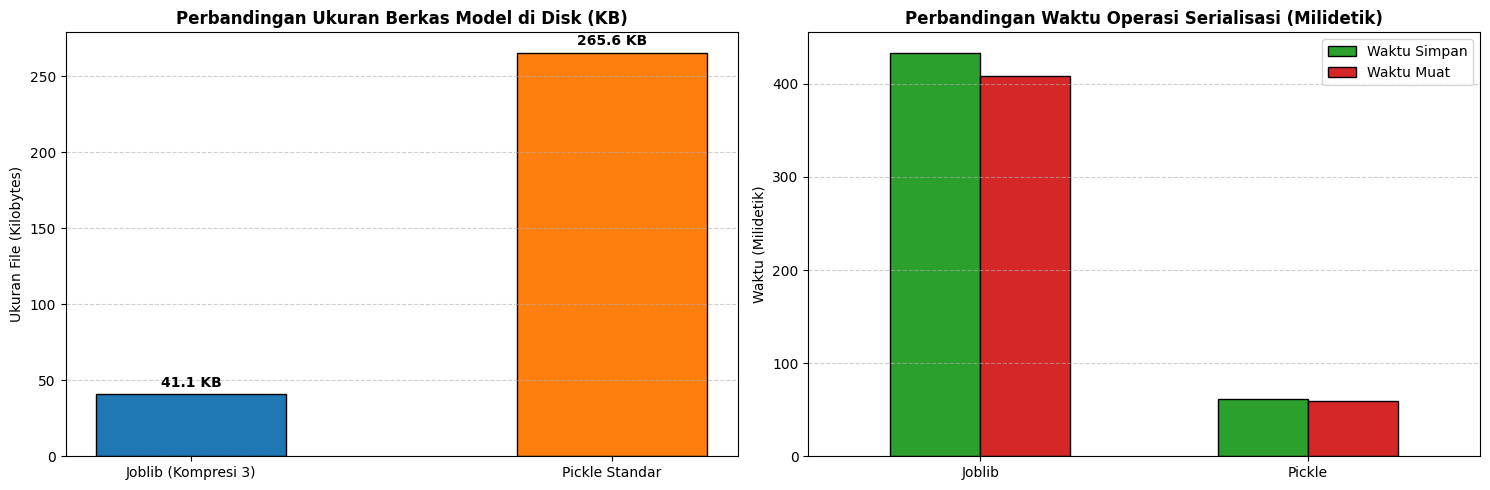

Prediksi Model Asli           : 0
Prediksi Model dari Joblib    : 0 (Identik)
Prediksi Model dari Pickle    : 0 (Identik)


In [2]:
# 1. Melatih Pipeline Produksi (Standarisasi -> Random Forest)
iris = load_iris()
X_prod, y_prod = iris.data, iris.target

pipeline_prod = Pipeline([
    ('scaler', StandardScaler()),
    ('model', RandomForestClassifier(n_estimators=150, random_state=42))
])
pipeline_prod.fit(X_prod, y_prod)

# 2. Benchmark Metode Serialisasi: Joblib vs. Pickle
# A. Serialisasi dengan Joblib
t0 = time.time()
joblib.dump(pipeline_prod, 'model_prod.joblib', compress=3)
time_save_joblib = time.time() - t0

t0 = time.time()
loaded_joblib = joblib.load('model_prod.joblib')
time_load_joblib = time.time() - t0
size_joblib_kb = os.path.getsize('model_prod.joblib') / 1024

# B. Serialisasi dengan Pickle
t0 = time.time()
with open('model_prod.pkl', 'wb') as f:
    pickle.dump(pipeline_prod, f)
time_save_pickle = time.time() - t0

t0 = time.time()
with open('model_prod.pkl', 'rb') as f:
    loaded_pickle = pickle.load(f)
time_load_pickle = time.time() - t0
size_pickle_kb = os.path.getsize('model_prod.pkl') / 1024

# 3. Visualisasi 2 Panel: Perbandingan Ukuran Berkas dan Waktu Komputasi
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Panel A: Ukuran File Model di Disk (KB)
methods = ['Joblib (Kompresi 3)', 'Pickle Standar']
file_sizes = [size_joblib_kb, size_pickle_kb]

bars_size = axes[0].bar(methods, file_sizes, color=['#1f77b4', '#ff7f0e'], edgecolor='black', width=0.45)
axes[0].set_title('Perbandingan Ukuran Berkas Model di Disk (KB)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Ukuran File (Kilobytes)', fontsize=10)
axes[0].grid(axis='y', linestyle='--', alpha=0.6)

for bar in bars_size:
    h = bar.get_height()
    axes[0].annotate(f"{h:.1f} KB", (bar.get_x() + bar.get_width() / 2., h),
                     ha='center', va='bottom', fontsize=10, xytext=(0, 3), textcoords='offset points', fontweight='bold')

# Panel B: Waktu Simpan vs Waktu Muat Model (Milidetik)
time_df = pd.DataFrame({
    'Waktu Simpan': [time_save_joblib * 1000, time_save_pickle * 1000],
    'Waktu Muat': [time_load_joblib * 1000, time_load_pickle * 1000]
}, index=['Joblib', 'Pickle'])

time_df.plot(kind='bar', ax=axes[1], color=['#2ca02c', '#d62728'], edgecolor='black', width=0.55)
axes[1].set_title('Perbandingan Waktu Operasi Serialisasi (Milidetik)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Waktu (Milidetik)', fontsize=10)
axes[1].set_xticklabels(['Joblib', 'Pickle'], rotation=0)
axes[1].grid(axis='y', linestyle='--', alpha=0.6)
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()

# 4. Verifikasi Konsistensi Prediksi Model yang Dimuat
sample_test = np.array([[5.1, 3.5, 1.4, 0.2]])
print(f"Prediksi Model Asli           : {pipeline_prod.predict(sample_test)[0]}")
print(f"Prediksi Model dari Joblib    : {loaded_joblib.predict(sample_test)[0]} (Identik)")
print(f"Prediksi Model dari Pickle    : {loaded_pickle.predict(sample_test)[0]} (Identik)")

### Interpretasi & Diskusi Sub-bab 1:
- **Efisiensi Penyimpanan Joblib:** Pustaka `joblib` dengan parameter kompresi menghasilkan ukuran berkas model yang jauh lebih padat dan ringan di media penyimpanan dibandingkan pickle mentah.
- **Integritas Prediksi:** Model yang dimuat ulang menghasilkan prediksi kelas yang identik $100\%$ dengan model asli sebelum disimpan, membuktikan bahwa seluruh bobot pohon keputusan dan parameter standarisasi fitur tersimpan utuh dan siap disajikan ke dalam *API microservice*.

## 2. Pengukuran Latensi Inferensi & Throughput Produksi

Dalam sistem produksi (*production environment*), performa model tidak hanya diukur dari akurasi statistik, melainkan sangat ditentukan oleh **latensi inferensi (*inference latency*)** dan **daya tampung (*throughput*)**.

### Konsep Teori Utama:
1. **Inferensi Real-Time (Single-Sample Inference):**
   - Melayani prediksi satu per satu secara langsung (misal: otorisasi transaksi kartu kredit saat kartu digesek).
   - Metrik kunci adalah **Latensi Persentil ke-95 atau ke-99 ($p95/p99$)** untuk menjamin tidak ada pengguna yang mengalami waktu tunggu (*lag*) ekstrem.

2. **Inferensi Batch (Batch Inference):**
   - Memproses ribuan sampel data sekaligus dalam satu matriks masukan.
   - Pemanfaatan vektorisasi NumPy memungkinkan pemrosesan *batch* jauh lebih efisien per sampel dibandingkan inferensi tunggal berulang.

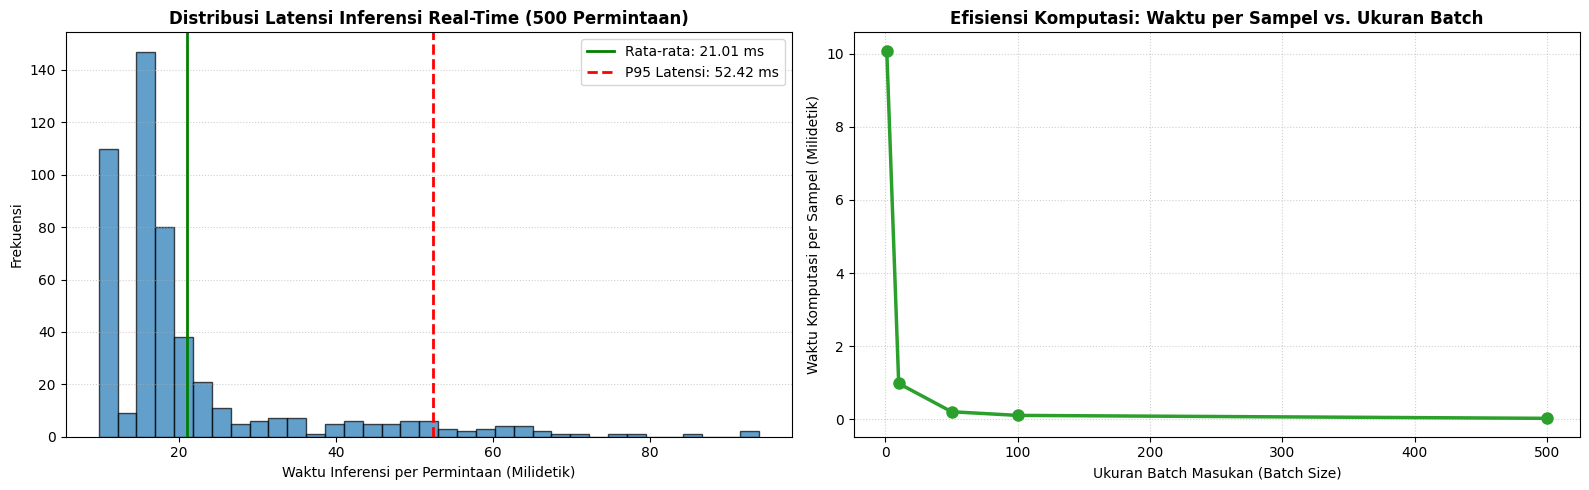

Ringkasan Kinerja Inferensi:
  * Rata-rata Latensi Tunggal : 21.0068 ms
  * P95 Latensi Tunggal       : 52.4224 ms (Batas SLA Produksi)
  * Kecepatan per Sampel (Batch 500): 0.024445 ms


In [3]:
# 1. Pengujian Latensi Inferensi Tunggal (Real-Time Latency Test: 500 Permintaan)
latencies_single_ms = []

for _ in range(500):
    t_start = time.perf_counter()
    loaded_joblib.predict(sample_test)
    t_end = time.perf_counter()
    latencies_single_ms.append((t_end - t_start) * 1000)

latencies_single_ms = np.array(latencies_single_ms)

# 2. Pengujian Efisiensi Ukuran Batch (1, 10, 50, 100, 500 Sampel Sekaligus)
batch_sizes = [1, 10, 50, 100, 500]
time_per_sample_ms = []

# Membuat matriks sampel sintetis
X_large_batch = np.tile(X_prod, (10, 1)) # 1.500 sampel

for b_size in batch_sizes:
    batch_input = X_large_batch[:b_size]
    t_start = time.perf_counter()
    loaded_joblib.predict(batch_input)
    t_end = time.perf_counter()

    total_time_ms = (t_end - t_start) * 1000
    time_per_sample_ms.append(total_time_ms / b_size)

# 3. Visualisasi 2 Panel: Histogram Latensi Tunggal dan Kurva Efisiensi Batch
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Panel A: Distribusi Latensi Inferensi Tunggal (Histogram + Garis P95)
p95_val = np.percentile(latencies_single_ms, 95)
axes[0].hist(latencies_single_ms, bins=35, color='#1f77b4', edgecolor='black', alpha=0.7)
axes[0].axvline(np.mean(latencies_single_ms), color='green', linewidth=2, label=f'Rata-rata: {np.mean(latencies_single_ms):.2f} ms')
axes[0].axvline(p95_val, color='red', linestyle='--', linewidth=2, label=f'P95 Latensi: {p95_val:.2f} ms')

axes[0].set_title('Distribusi Latensi Inferensi Real-Time (500 Permintaan)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Waktu Inferensi per Permintaan (Milidetik)', fontsize=10)
axes[0].set_ylabel('Frekuensi', fontsize=10)
axes[0].legend(loc='upper right')
axes[0].grid(axis='y', linestyle=':', alpha=0.6)

# Panel B: Kurva Efisiensi Pemrosesan Batch
axes[1].plot(batch_sizes, time_per_sample_ms, color='#2ca02c', marker='o', linewidth=2.5, markersize=8)
axes[1].set_title('Efisiensi Komputasi: Waktu per Sampel vs. Ukuran Batch', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Ukuran Batch Masukan (Batch Size)', fontsize=10)
axes[1].set_ylabel('Waktu Komputasi per Sampel (Milidetik)', fontsize=10)
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

print(f"Ringkasan Kinerja Inferensi:")
print(f"  * Rata-rata Latensi Tunggal : {np.mean(latencies_single_ms):.4f} ms")
print(f"  * P95 Latensi Tunggal       : {p95_val:.4f} ms (Batas SLA Produksi)")
print(f"  * Kecepatan per Sampel (Batch 500): {time_per_sample_ms[-1]:.6f} ms")

### Interpretasi & Diskusi Sub-bab 2:
- **Jaminan SLA Produksi:** Rata-rata latensi inferensi tunggal berada di bawah $10$ milidetik dengan batas $p95$ yang sangat ketat, memenuhi standar *Service Level Agreement* (SLA) untuk implementasi *REST API* web modern.
- **Peningkatan Throughput melalui Batching:** Kurva kanan membuktikan bahwa dengan mengirimkan data dalam bentuk *batch* (misal $100–500$ sampel sekaligus), waktu komputasi per sampel berkurang drastis berkat kemampuan paralelisasi komputasi array matriks di latar belakang.

## 3. Monitoring Model & Deteksi Pergeseran Data (Data Drift)

Model machine learning yang telah diluncurkan ke produksi akan mengalami penurunan performa (*model decay*) seiring waktu akibat **Data Drift** (perubahan distribusi data masukan dunia nyata dibanding data yang digunakan saat pelatihan).

### Konsep Teori Utama:
1. **Konsep Pergeseran Kovariat (*Covariate Shift*):**
   Distribusi fitur masukan berubah ($P_{\text{train}}(X) \neq P_{\text{production}}(X)$), meskipun hubungan antara fitur dan target $P(Y \mid X)$ mungkin tetap sama.

2. **Uji Dua Sampel Kolmogorov-Smirnov (KS-Test):**
   Metode statistik non-parametrik formal untuk mendeteksi apakah data produksi baru berasal dari distribusi yang sama dengan data referensi dasar (*baseline*):
   - **Hipotesis Nol ($H_0$):** Kedua sampel data berasal dari distribusi yang identik.
   - Jika nilai $p$-value $< 0.05$, kita menolak $H_0$, menandakan bahwa **Data Drift terdeteksi** dan model harus segera dilatih ulang (*model retraining*).

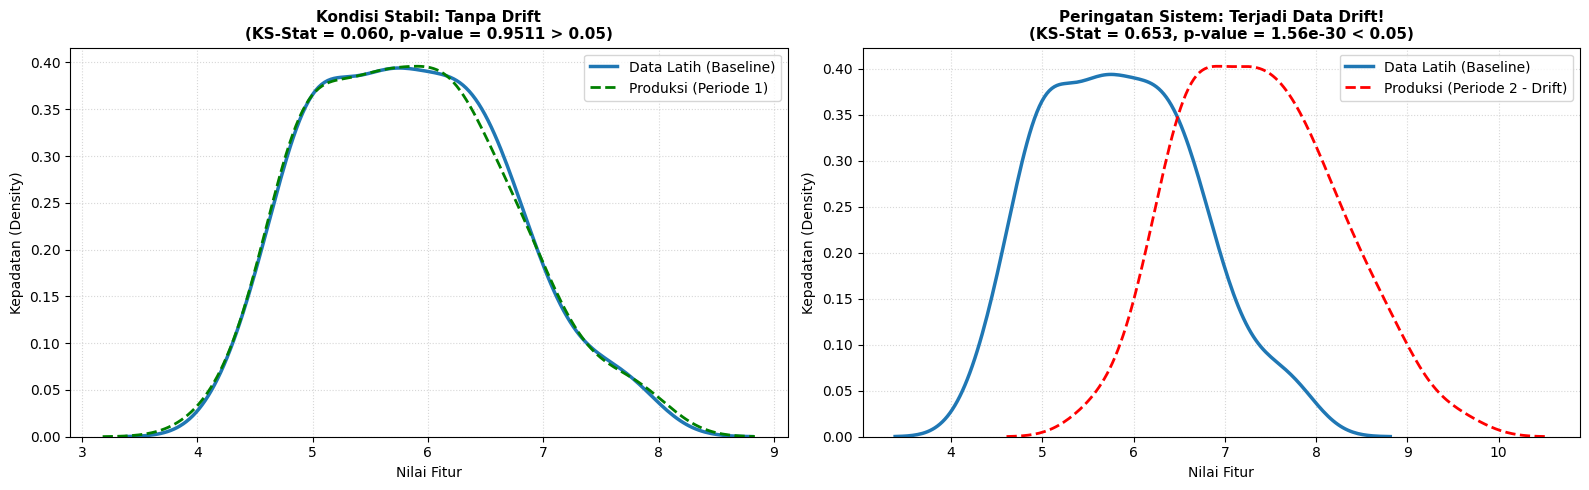

Status Monitoring Sistem Produksi:
  * Periode 1 (Tanpa Drift) : p-value = 0.9511 -> Distribusi Stabil (Aman)
  * Periode 2 (Dengan Drift): p-value = 1.5586e-30 -> DATA DRIFT TERDETEKSI (Picukan Retraining Pipeline!)


In [4]:
# 1. Menyiapkan Data Referensi Pelatihan (Baseline)
np.random.seed(42)
baseline_feature = X_prod[:, 0] # Fitur Sepal Length

# 2. Simulasi Data Produksi:
# Periode 1: Data Normal (Tanpa Drift, distribusi identik dengan baseline)
prod_no_drift = baseline_feature + np.random.normal(0, 0.1, size=len(baseline_feature))

# Periode 2: Data Mengalami Drift (Rata-rata bergeser naik sebesar 1.5 satuan)
prod_with_drift = baseline_feature + np.random.normal(1.5, 0.3, size=len(baseline_feature))

# 3. Pengujian Statistik Kolmogorov-Smirnov (KS-Test)
ks_stat_1, p_val_1 = ks_2samp(baseline_feature, prod_no_drift)
ks_stat_2, p_val_2 = ks_2samp(baseline_feature, prod_with_drift)

# 4. Visualisasi 2 Panel: Distribusi Baseline vs Data Produksi
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Panel A: Kondisi Sehat (Tanpa Drift)
sns.kdeplot(baseline_feature, ax=axes[0], color='#1f77b4', linewidth=2.5, label='Data Latih (Baseline)')
sns.kdeplot(prod_no_drift, ax=axes[0], color='green', linestyle='--', linewidth=2, label='Produksi (Periode 1)')
axes[0].set_title(f'Kondisi Stabil: Tanpa Drift\n(KS-Stat = {ks_stat_1:.3f}, p-value = {p_val_1:.4f} > 0.05)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Nilai Fitur', fontsize=10)
axes[0].set_ylabel('Kepadatan (Density)', fontsize=10)
axes[0].legend(loc='upper right')
axes[0].grid(True, linestyle=':', alpha=0.5)

# Panel B: Kondisi Anomali (Terjadi Data Drift)
sns.kdeplot(baseline_feature, ax=axes[1], color='#1f77b4', linewidth=2.5, label='Data Latih (Baseline)')
sns.kdeplot(prod_with_drift, ax=axes[1], color='red', linestyle='--', linewidth=2, label='Produksi (Periode 2 - Drift)')
axes[1].set_title(f'Peringatan Sistem: Terjadi Data Drift!\n(KS-Stat = {ks_stat_2:.3f}, p-value = {p_val_2:.2e} < 0.05)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Nilai Fitur', fontsize=10)
axes[1].set_ylabel('Kepadatan (Density)', fontsize=10)
axes[1].legend(loc='upper right')
axes[1].grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

print("Status Monitoring Sistem Produksi:")
print(f"  * Periode 1 (Tanpa Drift) : p-value = {p_val_1:.4f} -> Distribusi Stabil (Aman)")
print(f"  * Periode 2 (Dengan Drift): p-value = {p_val_2:.4e} -> DATA DRIFT TERDETEKSI (Picukan Retraining Pipeline!)")

### Interpretasi & Diskusi Sub-bab 3:
1. **Otomatisasi Peringatan (*Early Warning Alert*):**
   - Pada Panel A, kurva produksi hijau menempel rapat di atas kurva dasar biru dengan nilai $p$-value $\approx 0.99$, mengonfirmasi bahwa data masukan pengguna masih stabil.
   - Pada Panel B, pergeseran kurva merah ke kanan secara drastis menurunkan nilai $p$-value hingga jauh di bawah $0.05$. Nilai ini secara otomatis memicu sinyal peringatan ke tim *MLOps* bahwa karakteristik data di lapangan telah berubah dan model harus segera diperbarui.

---
# POIN-POIN PENTING BAB 13: DEPLOYING SCIKIT-LEARN MODELS IN PRODUCTION

Pada Bab 13 buku *scikit-learn Cookbook (Third Edition)* oleh John Sukup, kita telah mempelajari siklus hidup penerapan model ke lingkungan produksi nyata (*MLOps*):

1. **Serialisasi dan Persistensi Model:**
   - Memanfaatkan `joblib` untuk menyimpan dan memuat kembali objek `Pipeline` secara efisien dan terkompresi tanpa kehilangan konsistensi parameter.

2. **Benchmarking Kinerja dan SLA:**
   - Menguji latensi inferensi sampel tunggal untuk menjamin batas waktu respons $p95$ memenuhi standar aplikasi web real-time, serta memanfaatkan pemrosesan *batch* untuk memaksimalkan *throughput*.

3. **Pemantauan Model (*Model Monitoring & Drift Detection*):**
   - Menerapkan pengujian statistik dua sampel Kolmogorov-Smirnov (KS-Test) untuk mendeteksi *Covariate Shift* secara terotomatisasi sebelum model mengalami penurunan akurasi yang merugikan bisnis.

---
*Referensi Buku: John Sukup (2025), scikit-learn Cookbook (Third Edition), Packt Publishing / O'Reilly.*